# Polynomial Regression

**Regression Lab · Lesson 2** · College of Computer Studies, University of Technology Bahrain
Prepared by **Eng. Saeed Serwan Abdulsattar**

Interactive version: **https://saeedserwan.github.io/regression/polynomial.html**

In this notebook you will:

1. Diagnose a curved relationship with a residual plot.
2. Fit polynomials of increasing degree with NumPy and scikit-learn.
3. Choose the degree with adjusted R² and k-fold cross-validation.
4. See why extrapolating a polynomial is dangerous.
5. Control overfitting with ridge regularisation.

## 1. Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATASET = "speed_stopping_distance.csv"   # also try: hour_electricity_demand.csv, fertiliser_crop_yield.csv
local = Path("../data") / DATASET
url = f"https://raw.githubusercontent.com/SaeedSerwan/regression/main/data/{DATASET}"
df = pd.read_csv(local if local.exists() else url)
x_name, y_name = df.columns[:2]
x, y = df[x_name].to_numpy(float), df[y_name].to_numpy(float)
print(f"{len(df)} rows · x = {x_name} · y = {y_name}")
df.head()

24 rows · x = speed_km_h · y = stopping_distance_m


,speed_km_h,stopping_distance_m
0,82,79.1
1,25,22.2
2,30,12.8
3,116,122.8
4,52,28.5


## 2. A straight line, and what its residuals say

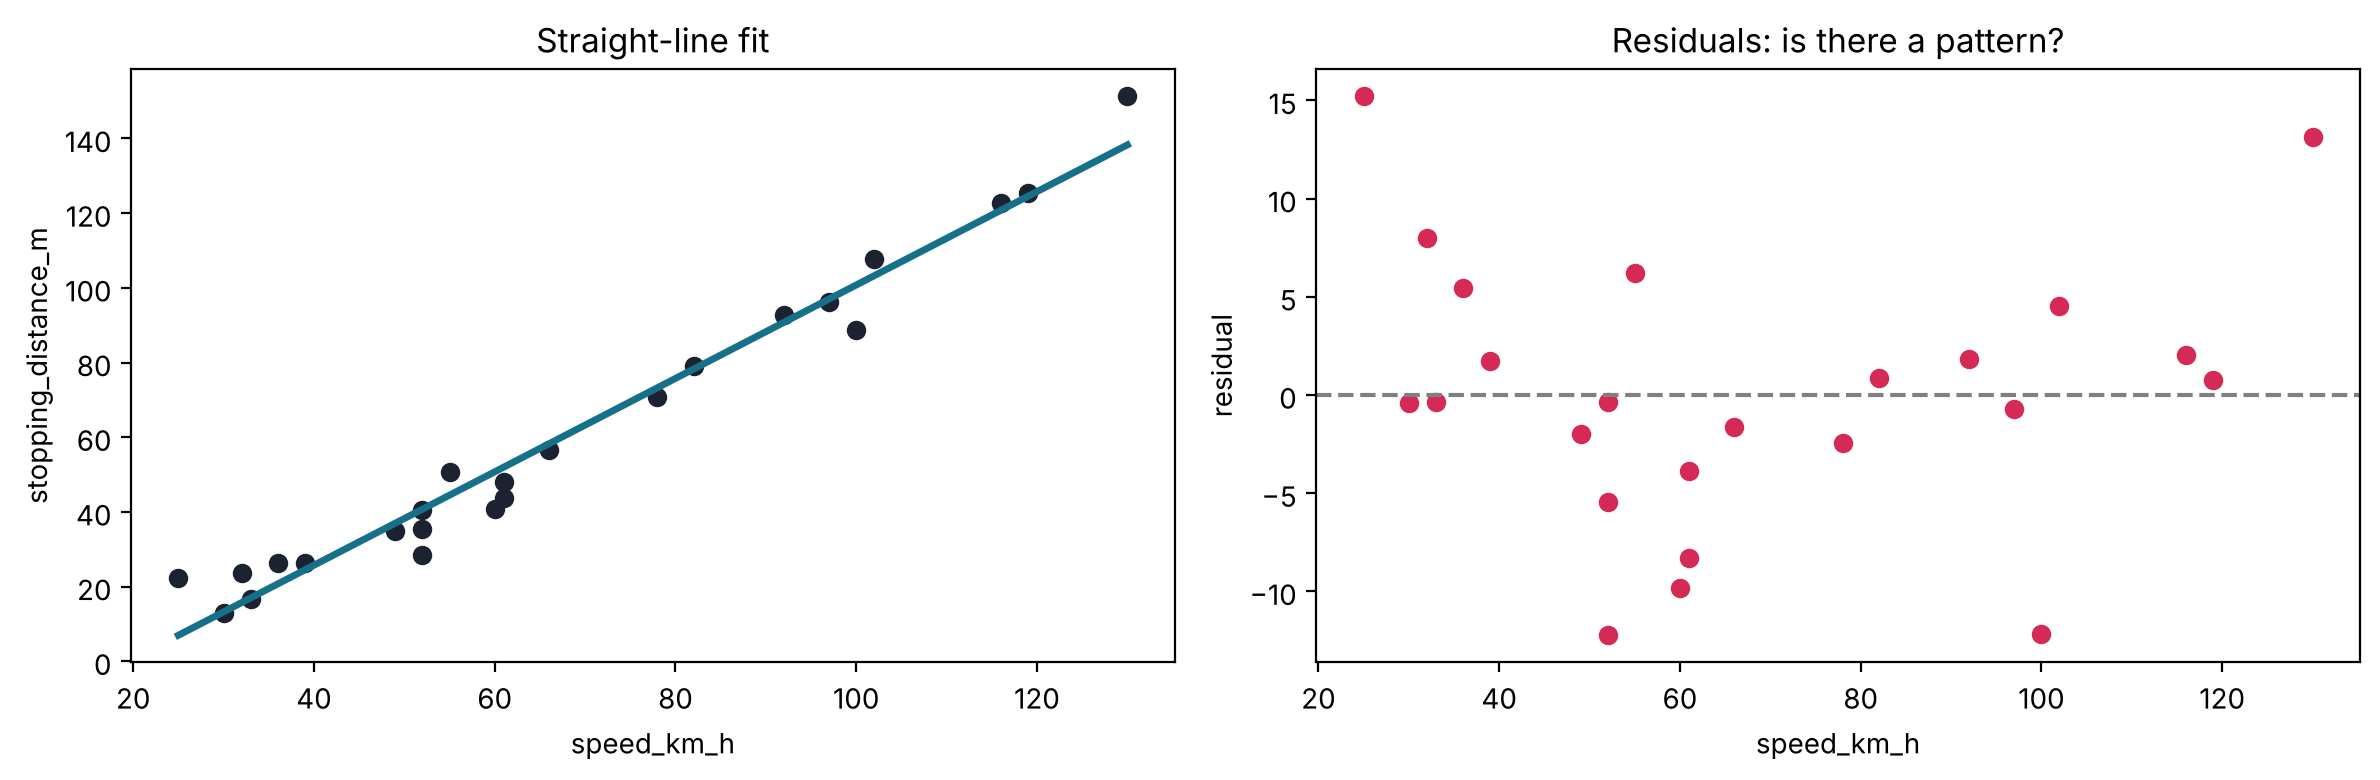

In [2]:
m, b = np.polyfit(x, y, 1)
resid = y - (m * x + b)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
order = np.argsort(x)
a1.scatter(x, y, color="#1c2230"); a1.plot(x[order], (m * x + b)[order], color="#17708a", lw=2.5)
a1.set(xlabel=x_name, ylabel=y_name, title="Straight-line fit")
a2.scatter(x, resid, color="#d52a55"); a2.axhline(0, color="grey", ls="--")
a2.set(xlabel=x_name, ylabel="residual", title="Residuals: is there a pattern?")
plt.tight_layout(); plt.show()

A systematic shape in the residuals (here: positive at both ends, negative in the middle) means the line is missing curvature.

## 3. Polynomials are linear regression on engineered features

$$\hat y = \beta_0 + \beta_1 x + \beta_2 x^2 + \dots + \beta_d x^d$$

`PolynomialFeatures` builds the columns $x, x^2, \dots, x^d$; `StandardScaler` puts them on the same scale; `LinearRegression` fits the coefficients.

In [3]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score

X = x.reshape(-1, 1)
print(pd.DataFrame(PolynomialFeatures(4, include_bias=False).fit_transform(X)[:5],
                   columns=["x", "x²", "x³", "x⁴"]).round(1))

def poly_model(degree, alpha=None):
    final = LinearRegression() if alpha is None else Ridge(alpha=alpha)
    return make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), final)

       x       x²         x³           x⁴
0   82.0   6724.0   551368.0   45212176.0
1   25.0    625.0    15625.0     390625.0
2   30.0    900.0    27000.0     810000.0
3  116.0  13456.0  1560896.0  181063936.0
4   52.0   2704.0   140608.0    7311616.0


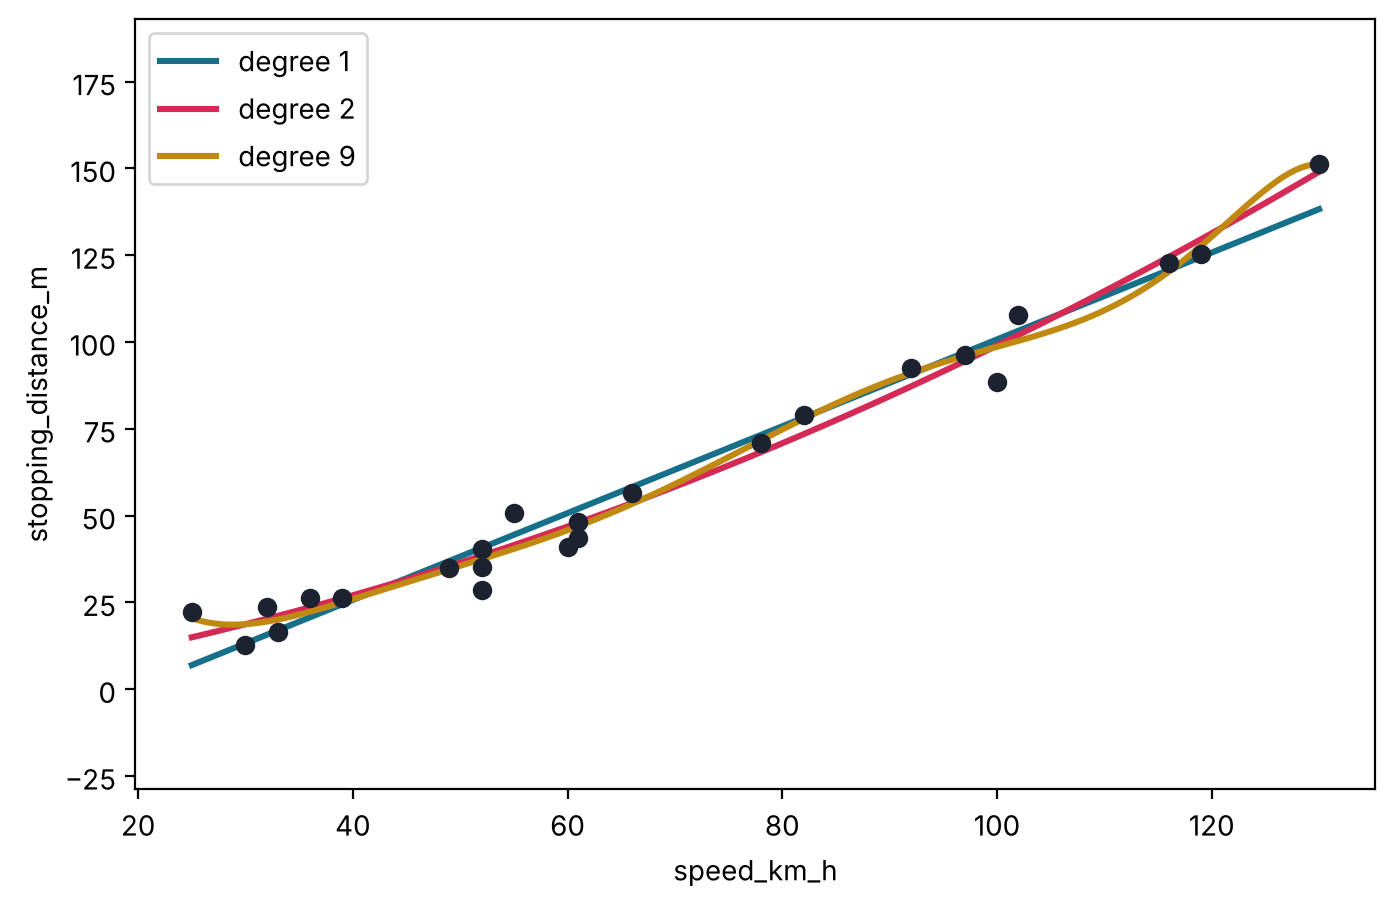

In [4]:
grid = np.linspace(x.min(), x.max(), 300).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, color="#1c2230", zorder=3)
for d, col in [(1, "#17708a"), (2, "#d52a55"), (9, "#c08a12")]:
    ax.plot(grid, poly_model(d).fit(X, y).predict(grid), color=col, lw=2.2, label=f"degree {d}")
ax.set(xlabel=x_name, ylabel=y_name, ylim=(y.min() - 0.3 * np.ptp(y), y.max() + 0.3 * np.ptp(y))); ax.legend()
plt.show()

## 4. Choosing the degree

In [5]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=0)
n, rows = len(y), []
for d in range(1, 11):
    model = poly_model(d).fit(X, y)
    pred = model.predict(X)
    r2 = r2_score(y, pred)
    rows.append({
        "degree": d,
        "train RMSE": np.sqrt(mean_squared_error(y, pred)),
        "CV RMSE": -cross_val_score(poly_model(d), X, y, cv=cv, scoring="neg_root_mean_squared_error").mean(),
        "R²": r2,
        "adjusted R²": 1 - (1 - r2) * (n - 1) / (n - d - 1),
    })
table = pd.DataFrame(rows).set_index("degree")
print("Best degree by CV RMSE:", table["CV RMSE"].idxmin(), " · by adjusted R²:", table["adjusted R²"].idxmax())
table.round(4)

Best degree by CV RMSE: 4  · by adjusted R²: 4


,train RMSE,CV RMSE,R²,adjusted R²
degree,,,,
1,6.7395,7.2360,0.9690,0.9676
2,5.1008,5.8547,0.9822,0.9805
3,5.0461,6.7928,0.9826,0.9800
4,4.7023,5.6538,0.9849,0.9817
5,4.6819,6.1872,0.9850,0.9809
6,4.6784,14.3171,0.9851,0.9798
7,4.5237,51.3572,0.9860,0.9799
8,4.5515,64.1002,0.9859,0.9783
9,4.5777,78.0665,0.9857,0.9765


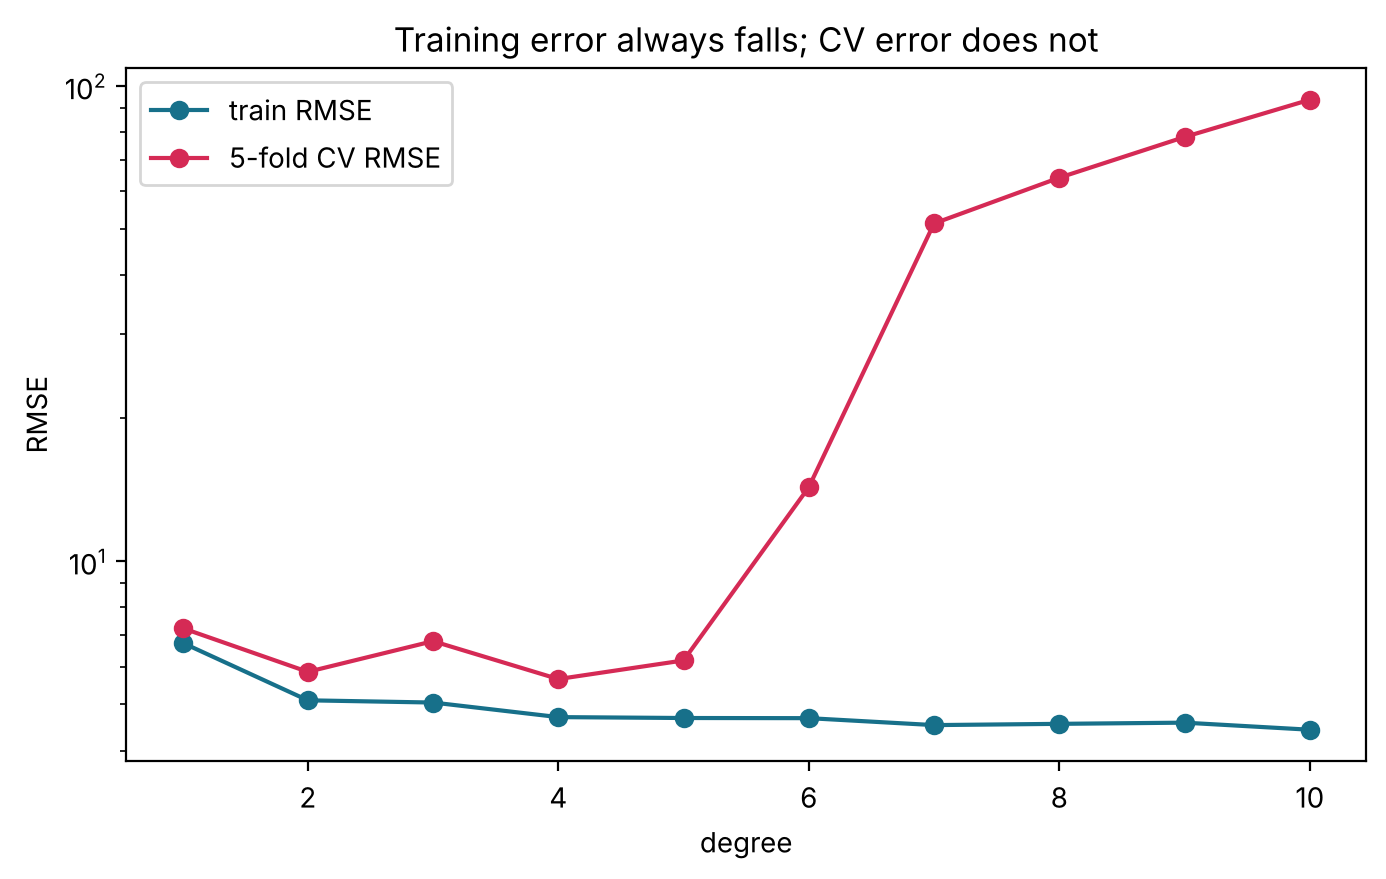

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(table.index, table["train RMSE"], "o-", color="#17708a", label="train RMSE")
ax.plot(table.index, table["CV RMSE"], "o-", color="#d52a55", label="5-fold CV RMSE")
ax.set(yscale="log", xlabel="degree", ylabel="RMSE", title="Training error always falls; CV error does not"); ax.legend()
plt.show()

## 5. Beware extrapolation

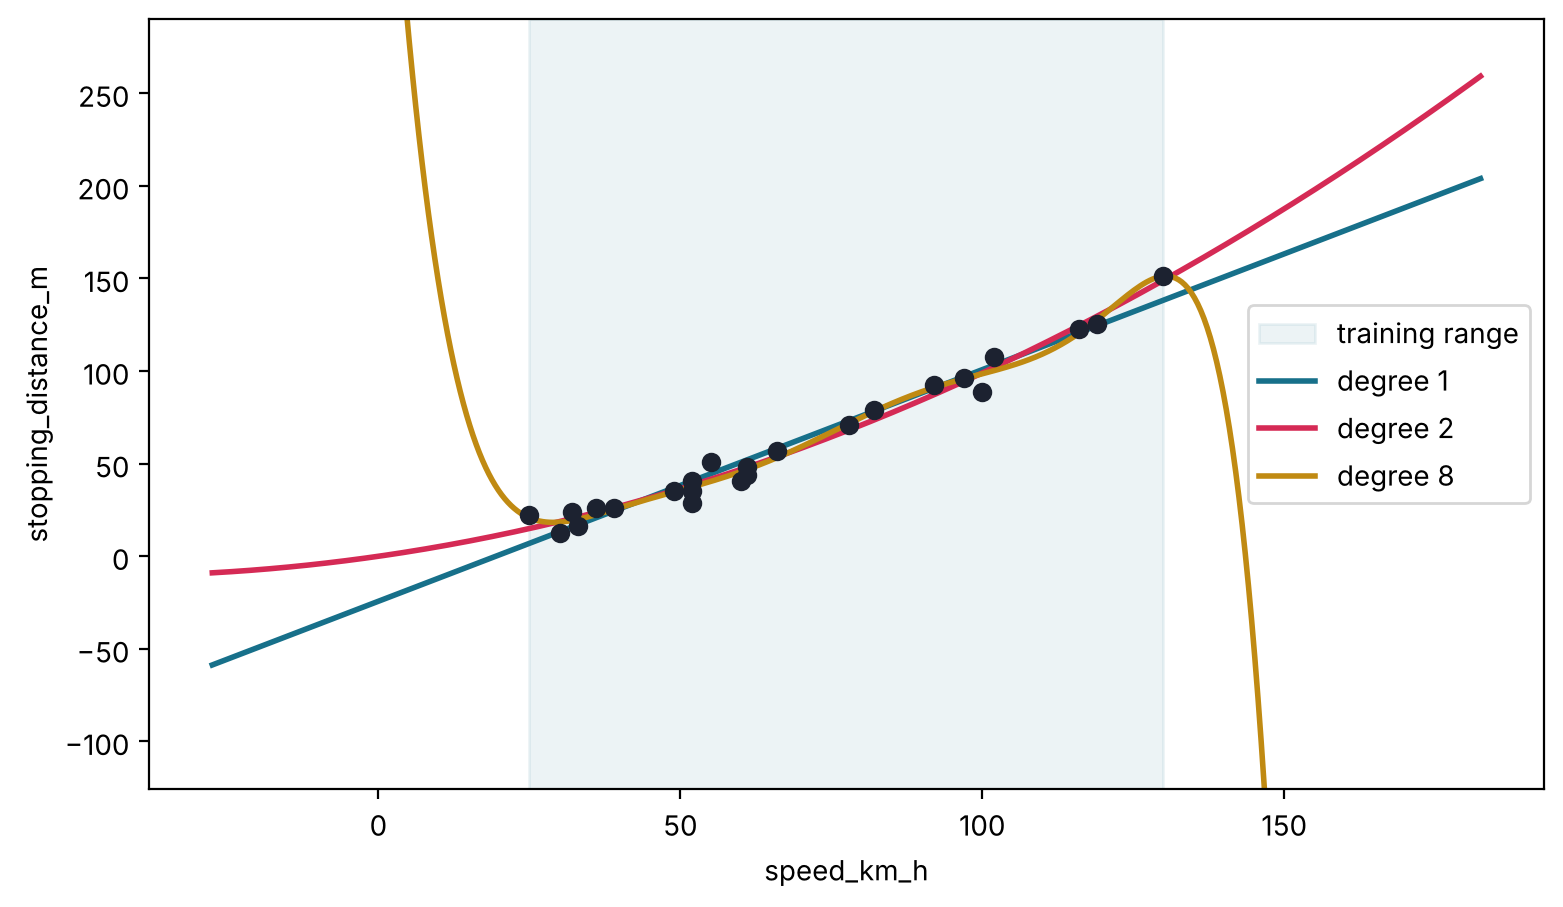

In [7]:
span = np.ptp(x)
wide = np.linspace(x.min() - 0.5 * span, x.max() + 0.5 * span, 400).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(9, 5))
ax.axvspan(x.min(), x.max(), color="#17708a", alpha=0.08, label="training range")
ax.scatter(x, y, color="#1c2230", zorder=3)
for d, col in [(1, "#17708a"), (2, "#d52a55"), (8, "#c08a12")]:
    ax.plot(wide, poly_model(d).fit(X, y).predict(wide), color=col, lw=2, label=f"degree {d}")
ax.set(ylim=(y.min() - np.ptp(y), y.max() + np.ptp(y)), xlabel=x_name, ylabel=y_name); ax.legend()
plt.show()

## 6. Ridge regularisation

$$\min_\beta \sum_i (y_i-\hat y_i)^2 + \lambda\sum_{j\ge1}\beta_j^2$$

In scikit-learn the penalty λ is called `alpha`.

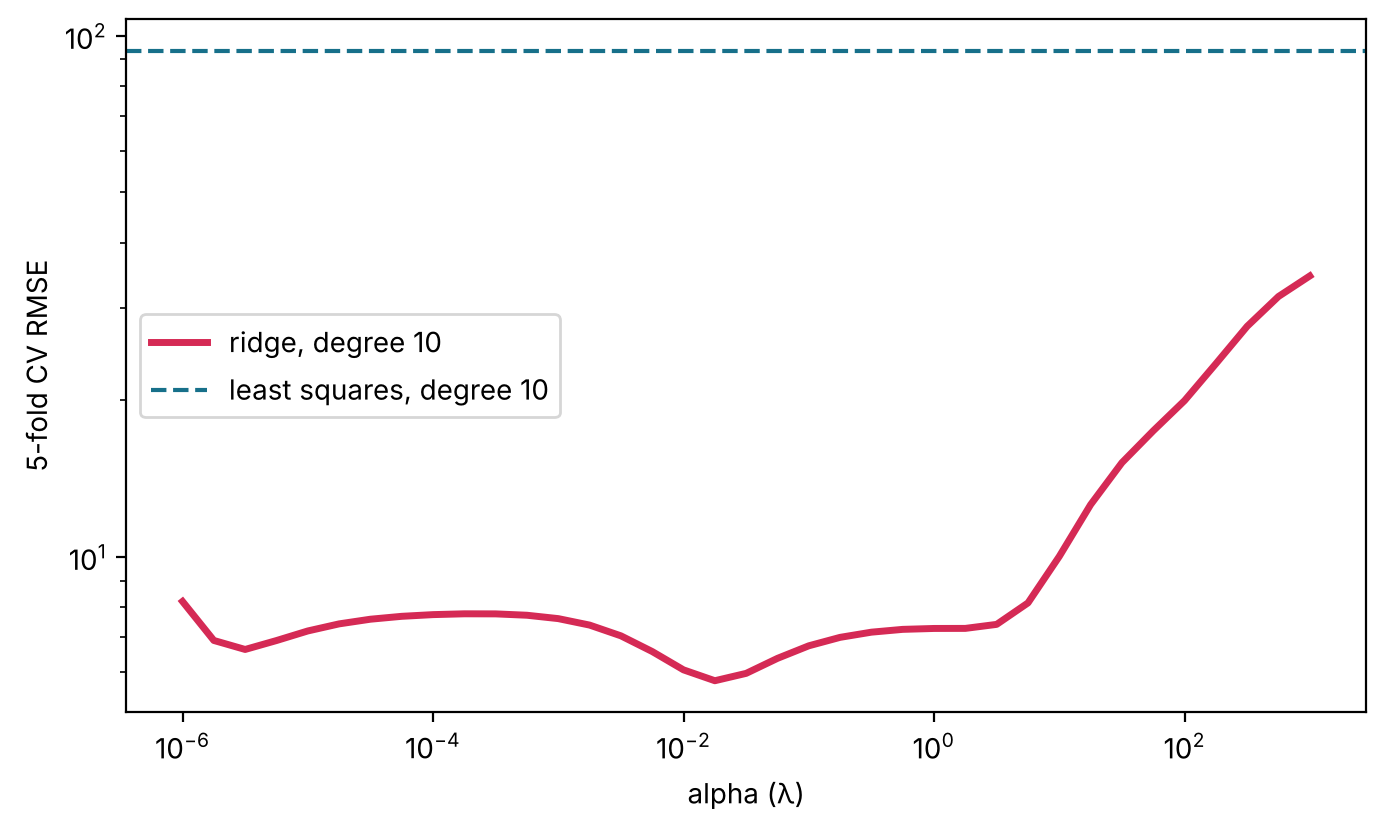

Best alpha ≈ 0.0178: CV RMSE 5.782 vs 93.515 without regularisation


In [8]:
alphas = np.logspace(-6, 3, 37)
scores = [-cross_val_score(poly_model(10, a), X, y, cv=cv, scoring="neg_root_mean_squared_error").mean() for a in alphas]
best = alphas[int(np.argmin(scores))]
ols_cv = -cross_val_score(poly_model(10), X, y, cv=cv, scoring="neg_root_mean_squared_error").mean()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogx(alphas, scores, color="#d52a55", lw=2.5, label="ridge, degree 10")
ax.axhline(ols_cv, color="#17708a", ls="--", label="least squares, degree 10")
ax.set(yscale="log", xlabel="alpha (λ)", ylabel="5-fold CV RMSE"); ax.legend()
plt.show()
print(f"Best alpha ≈ {best:.3g}: CV RMSE {min(scores):.3f} vs {ols_cv:.3f} without regularisation")

## 7. Exercises

1. Switch `DATASET` to `hour_electricity_demand.csv`. Which degree does cross-validation choose, and why is it higher than for stopping distance?
2. Load `study_hours_exam_score.csv` (a truly linear relationship). What do the CV curve and adjusted R² recommend?
3. Fit degree 2 to `projectile_height_time.csv`. Compare your coefficients with the physics formula h = h₀ + v₀t − ½gt². What value of g do you get?
4. Using the stopping-distance data, predict the distance at 200 km/h with degrees 1, 2 and 8. How much do they disagree? Which would you trust, and why?
5. Repeat section 6 with `Lasso` instead of `Ridge`. Which coefficients become exactly zero?